In [53]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [54]:
df = pd.read_csv("ai_developer_productivity.csv")

In [55]:
df.head()

,Developer_ID,Date,Hours_Coding,AI_Usage_Hours,Lines_of_Code,Commits,Bugs_Reported,Sleep_Hours,Distractions,Cognitive_Load,Stress_Level,Task_Success
0,DEV-126,2026-01-12,4.5,3.8,638,5,4,6,3,6,6,0
1,DEV-155,2026-01-12,2.7,3.5,438,0,4,3,8,8,8,0
2,DEV-199,2026-02-03,7.9,2.0,680,4,3,8,2,2,2,1
3,DEV-180,2026-01-13,3.1,7.9,765,1,5,8,4,3,5,0
4,DEV-144,2026-03-29,5.9,2.7,495,3,8,5,7,9,9,0


In [56]:
df.shape

(1000, 12)

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Developer_ID    1000 non-null   str    
 1   Date            1000 non-null   str    
 2   Hours_Coding    1000 non-null   float64
 3   AI_Usage_Hours  1000 non-null   float64
 4   Lines_of_Code   1000 non-null   int64  
 5   Commits         1000 non-null   int64  
 6   Bugs_Reported   1000 non-null   int64  
 7   Sleep_Hours     1000 non-null   int64  
 8   Distractions    1000 non-null   int64  
 9   Cognitive_Load  1000 non-null   int64  
 10  Stress_Level    1000 non-null   int64  
 11  Task_Success    1000 non-null   int64  
dtypes: float64(2), int64(8), str(2)
memory usage: 93.9 KB


In [58]:
df.describe()

,Hours_Coding,AI_Usage_Hours,Lines_of_Code,Commits,Bugs_Reported,Sleep_Hours,Distractions,Cognitive_Load,Stress_Level,Task_Success
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,4.985200,3.626300,639.462000,3.556000,3.685000,6.506000,4.105000,5.705000,5.464000,0.472000
std,1.392257,1.921919,253.068711,2.284312,2.737018,1.704368,2.663657,2.190153,2.124905,0.499465
min,2.000000,0.500000,132.000000,0.000000,0.000000,3.000000,0.000000,2.000000,2.000000,0.000000
25%,4.000000,2.200000,454.000000,2.000000,2.000000,5.000000,2.000000,4.000000,4.000000,0.000000
50%,4.900000,3.200000,596.000000,4.000000,3.000000,7.000000,4.000000,5.000000,5.000000,0.000000
75%,5.925000,5.000000,776.500000,5.000000,5.000000,8.000000,6.000000,7.000000,7.000000,1.000000
max,8.000000,8.000000,1450.000000,9.000000,20.000000,9.000000,10.000000,10.000000,10.000000,1.000000


In [59]:
df.isnull().sum()

Developer_ID      0
Date              0
Hours_Coding      0
AI_Usage_Hours    0
Lines_of_Code     0
Commits           0
Bugs_Reported     0
Sleep_Hours       0
Distractions      0
Cognitive_Load    0
Stress_Level      0
Task_Success      0
dtype: int64

In [60]:
print(df.duplicated().sum())

0


In [61]:
df.drop(["Developer_ID", "Date"], axis=1, inplace=True)

In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Hours_Coding    1000 non-null   float64
 1   AI_Usage_Hours  1000 non-null   float64
 2   Lines_of_Code   1000 non-null   int64  
 3   Commits         1000 non-null   int64  
 4   Bugs_Reported   1000 non-null   int64  
 5   Sleep_Hours     1000 non-null   int64  
 6   Distractions    1000 non-null   int64  
 7   Cognitive_Load  1000 non-null   int64  
 8   Stress_Level    1000 non-null   int64  
 9   Task_Success    1000 non-null   int64  
dtypes: float64(2), int64(8)
memory usage: 78.3 KB


In [63]:
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} Outliers")


Hours_Coding: 0 Outliers
AI_Usage_Hours: 0 Outliers
Lines_of_Code: 23 Outliers
Commits: 0 Outliers
Bugs_Reported: 41 Outliers
Sleep_Hours: 0 Outliers
Distractions: 0 Outliers
Cognitive_Load: 0 Outliers
Stress_Level: 0 Outliers
Task_Success: 0 Outliers


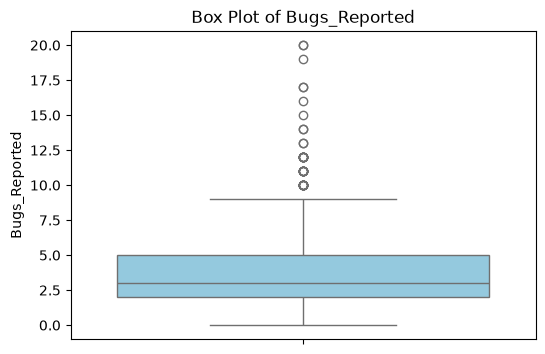

In [64]:
plt.figure(figsize=(6,4))
sns.boxplot(y=df["Bugs_Reported"], color="skyblue")
plt.title("Box Plot of Bugs_Reported")
plt.ylabel("Bugs_Reported")
plt.show()

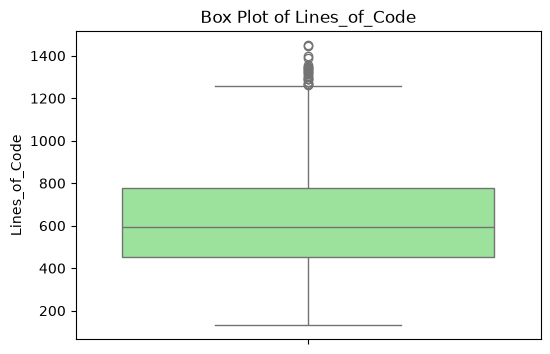

In [65]:
plt.figure(figsize=(6,4))
sns.boxplot(y=df["Lines_of_Code"], color="lightgreen")
plt.title("Box Plot of Lines_of_Code")
plt.ylabel("Lines_of_Code")
plt.show()

In [66]:
df.describe()

,Hours_Coding,AI_Usage_Hours,Lines_of_Code,Commits,Bugs_Reported,Sleep_Hours,Distractions,Cognitive_Load,Stress_Level,Task_Success
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,4.985200,3.626300,639.462000,3.556000,3.685000,6.506000,4.105000,5.705000,5.464000,0.472000
std,1.392257,1.921919,253.068711,2.284312,2.737018,1.704368,2.663657,2.190153,2.124905,0.499465
min,2.000000,0.500000,132.000000,0.000000,0.000000,3.000000,0.000000,2.000000,2.000000,0.000000
25%,4.000000,2.200000,454.000000,2.000000,2.000000,5.000000,2.000000,4.000000,4.000000,0.000000
50%,4.900000,3.200000,596.000000,4.000000,3.000000,7.000000,4.000000,5.000000,5.000000,0.000000
75%,5.925000,5.000000,776.500000,5.000000,5.000000,8.000000,6.000000,7.000000,7.000000,1.000000
max,8.000000,8.000000,1450.000000,9.000000,20.000000,9.000000,10.000000,10.000000,10.000000,1.000000


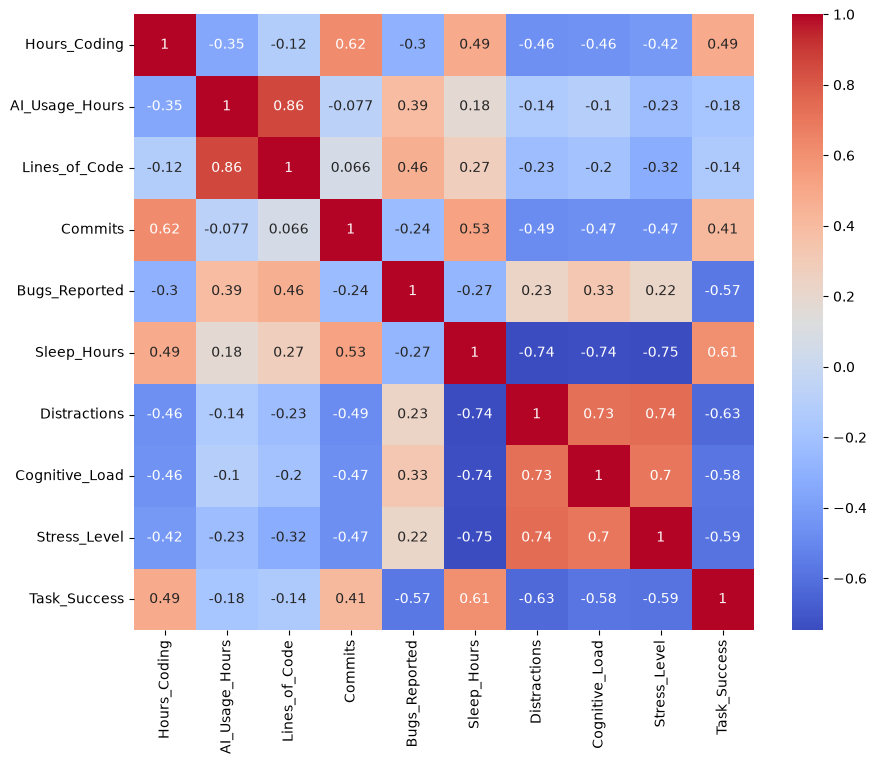

In [67]:
corr = df.corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

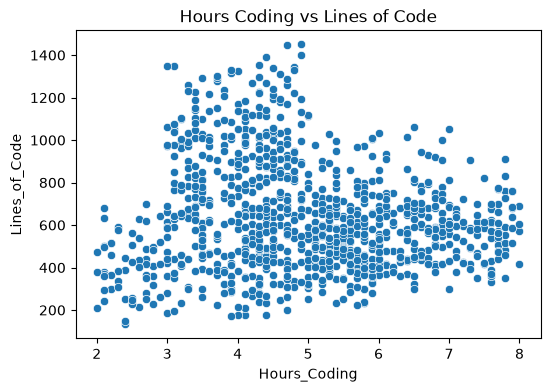

In [68]:
plt.figure(figsize=(6,4))

sns.scatterplot(
    data=df,
    x="Hours_Coding",
    y="Lines_of_Code"
)

plt.title("Hours Coding vs Lines of Code")
plt.show()

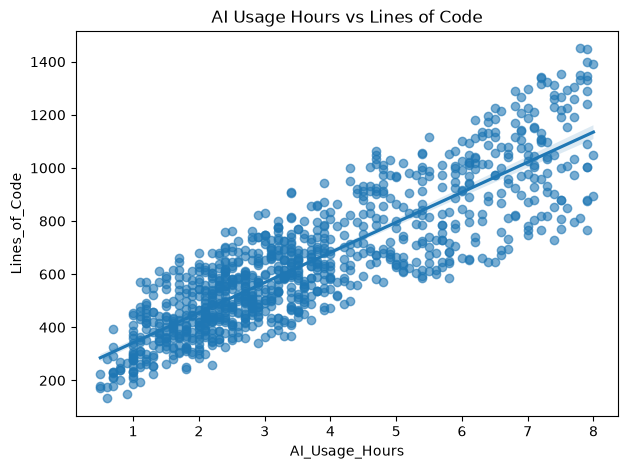

In [69]:
plt.figure(figsize=(7,5))

sns.regplot(
    data=df,
    x="AI_Usage_Hours",
    y="Lines_of_Code",
    scatter_kws={"alpha":0.6}
)

plt.title("AI Usage Hours vs Lines of Code")
plt.show()

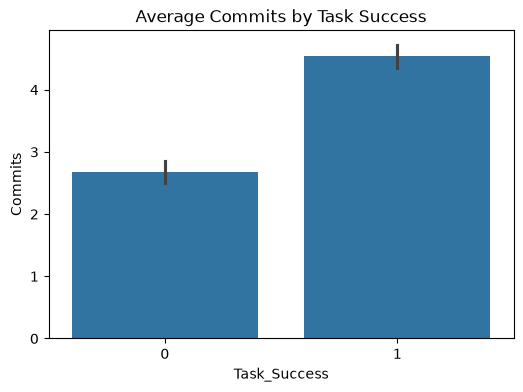

In [70]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=df,
    x="Task_Success",
    y="Commits"
)

plt.title("Average Commits by Task Success")
plt.show()

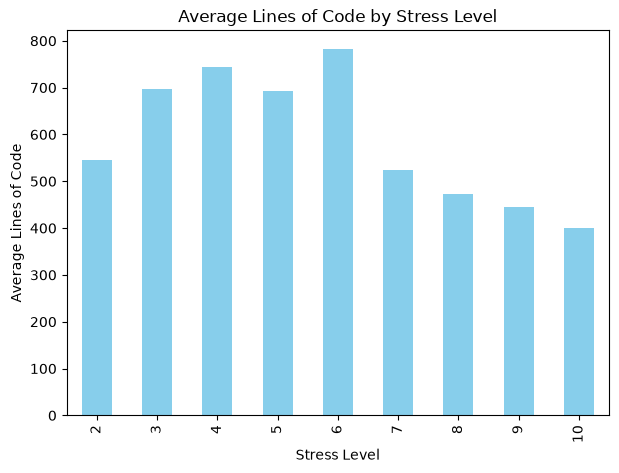

In [71]:
avg_loc = df.groupby("Stress_Level")["Lines_of_Code"].mean()

plt.figure(figsize=(7,5))
avg_loc.plot(kind="bar", color="skyblue")

plt.title("Average Lines of Code by Stress Level")
plt.xlabel("Stress Level")
plt.ylabel("Average Lines of Code")

plt.show()

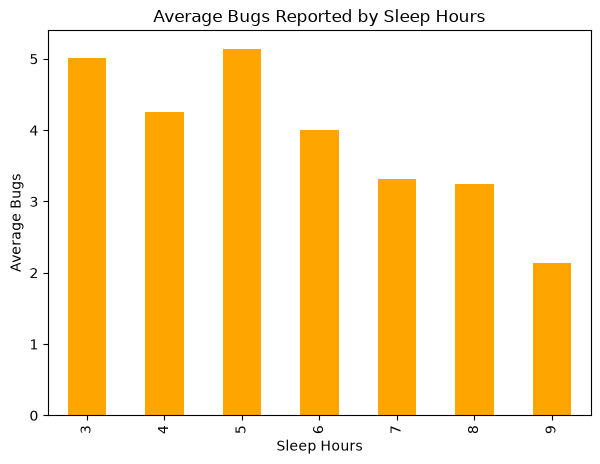

In [72]:
avg_bugs = df.groupby("Sleep_Hours")["Bugs_Reported"].mean()

plt.figure(figsize=(7,5))
avg_bugs.plot(kind="bar", color="orange")

plt.title("Average Bugs Reported by Sleep Hours")
plt.xlabel("Sleep Hours")
plt.ylabel("Average Bugs")

plt.show()

model

In [73]:
X = df.drop("Task_Success", axis=1)
y = df["Task_Success"]

In [74]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [75]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    min_samples_split=8,
    min_samples_leaf=3,
    random_state=42
) 
    

In [76]:
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [77]:
y_pred = model.predict(X_test)

In [78]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.97


check for overfitting and data leakage

In [79]:
print("Train Accuracy:", model.score(X_train, y_train))
print("Test Accuracy :", model.score(X_test, y_test))

Train Accuracy: 0.99375
Test Accuracy : 0.97


In [80]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("Scores:", scores)
print("Mean Accuracy:", scores.mean())
print("Std:", scores.std())

Scores: [0.94  0.97  0.975 0.95  0.955]
Mean Accuracy: 0.958
Std: 0.012884098726725137


In [81]:
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

y_shuffled = shuffle(y, random_state=42)

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X,
    y_shuffled,
    test_size=0.2,
    random_state=42
)

test_model = RandomForestClassifier(random_state=42)
test_model.fit(X_train_s, y_train_s)

print("Accuracy after shuffling target:",
      test_model.score(X_test_s, y_test_s))

Accuracy after shuffling target: 0.48


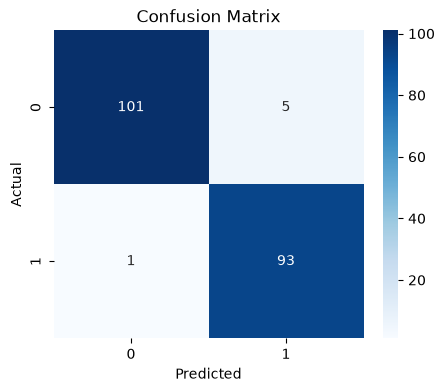

In [82]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

model 2


In [83]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


In [84]:
X = df.drop("Task_Success", axis=1)
y = df["Task_Success"]

In [85]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [86]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [87]:
log_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

In [88]:
log_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [89]:
y_pred = log_model.predict(X_test_scaled)

In [90]:
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy)

Logistic Regression Accuracy: 0.985


check if has overfitting or data leakage

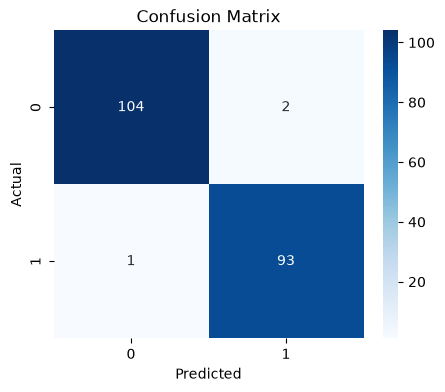

In [91]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [92]:
print("Train Accuracy:",
      log_model.score(X_train_scaled, y_train))

print("Test Accuracy:",
      log_model.score(X_test_scaled, y_test))

Train Accuracy: 0.98125
Test Accuracy: 0.985


In [93]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        random_state=42,
        max_iter=1000
    ))
])

scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("Scores:", scores)
print("Mean Accuracy:", scores.mean())
print("Std:", scores.std())

Scores: [0.97  0.975 0.99  0.96  0.985]
Mean Accuracy: 0.976
Std: 0.01067707825203132


In [94]:
from sklearn.utils import shuffle

y_shuffled = shuffle(y, random_state=42)

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X,
    y_shuffled,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train_s)
X_test_s = scaler.transform(X_test_s)

test_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

test_model.fit(X_train_s, y_train_s)

print("Accuracy after shuffling target:",
      test_model.score(X_test_s, y_test_s))

Accuracy after shuffling target: 0.54


save logistic model

In [95]:
import joblib


joblib.dump(log_model, "logistic_regression_model.pkl")


joblib.dump(scaler, "scaler.pkl")

print("Model and Scaler saved successfully!")

Model and Scaler saved successfully!


In [96]:
loaded_model = joblib.load("logistic_regression_model.pkl")
loaded_scaler = joblib.load("scaler.pkl")

In [97]:
new_data = [[
    5.5,   
    3.2,   
    650, 
    4,     
    2,    
    7,     
    3,     
    4,    
    5      
]]

new_data = loaded_scaler.transform(new_data)

prediction = loaded_model.predict(new_data)

print(prediction)

[1]


C:\Users\Compumart\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
